In [44]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** This project involves building a supervised binary classification model to predict whether a breast mass is malignant (0) or benign (1) based on 30 numeric features derived from digitized Fine-Needle Aspirate (FNA) images. A false negative is significantly more costly than a false positive because missing an active cancer diagnosis delays life-saving medical intervention. Model success will primarily be judged by maximizing recall on the malignant class and ROC-AUC, while maintaining high overall classification accuracy.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
# Classifier imports
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [2]:
# TODO: load the dataset and copy its DataFrame into df
# Load dataset as a pandas DataFrame
data = load_breast_cancer(as_frame=True)
df = data.frame
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [3]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
# Print shape, dtypes counts, and first 5 rows
print("Shape:", df.shape)
print("\nData Types Count:\n", df.dtypes.value_counts())
display(df.head())

Shape: (569, 31)

Data Types Count:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [4]:
# TODO: class counts and percentages
# Class counts and percentages
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({'Count': counts, 'Percentage (%)': proportions})
summary_df.index = summary_df.index.map({0: '0 (Malignant)', 1: '1 (Benign)'})
display(summary_df)

,Count,Percentage (%)
target,,
1 (Benign),357,62.741652
0 (Malignant),212,37.258348


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [5]:
# TODO: describe().T, then the 10 largest skewness values
# Transposed summary statistics
display(df.describe().T)

# 10 largest skewness values (excluding target)
skewed = df.drop(columns=['target']).skew().abs().sort_values(ascending=False).head(10)
print("\nTop 10 Most Skewed Features:\n", skewed)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Top 10 Most Skewed Features:
 area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [6]:
# TODO: correlation with target, sorted
# Correlation with target, sorted
correlations = df.corr()['target'].drop('target').sort_values()

print("5 Most Negative Correlations with Target:")
print(correlations.head(5))

print("\n5 Most Positive Correlations with Target:")
print(correlations.tail(5))

5 Most Negative Correlations with Target:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations with Target:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** The dataset shows a mild class imbalance (~63% benign vs ~37% malignant), which means standard accuracy can be overly optimistic and primary evaluation should rely on metrics like Recall, F1-Score, or ROC-AUC to avoid missing malignant cases. Additionally, several features display significant positive skewness, indicating long-tailed distributions. Applying power transforms (like Log or Box-Cox) or robust scaling will help normalize these feature distributions, improving performance for distance-based and linear algorithms.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

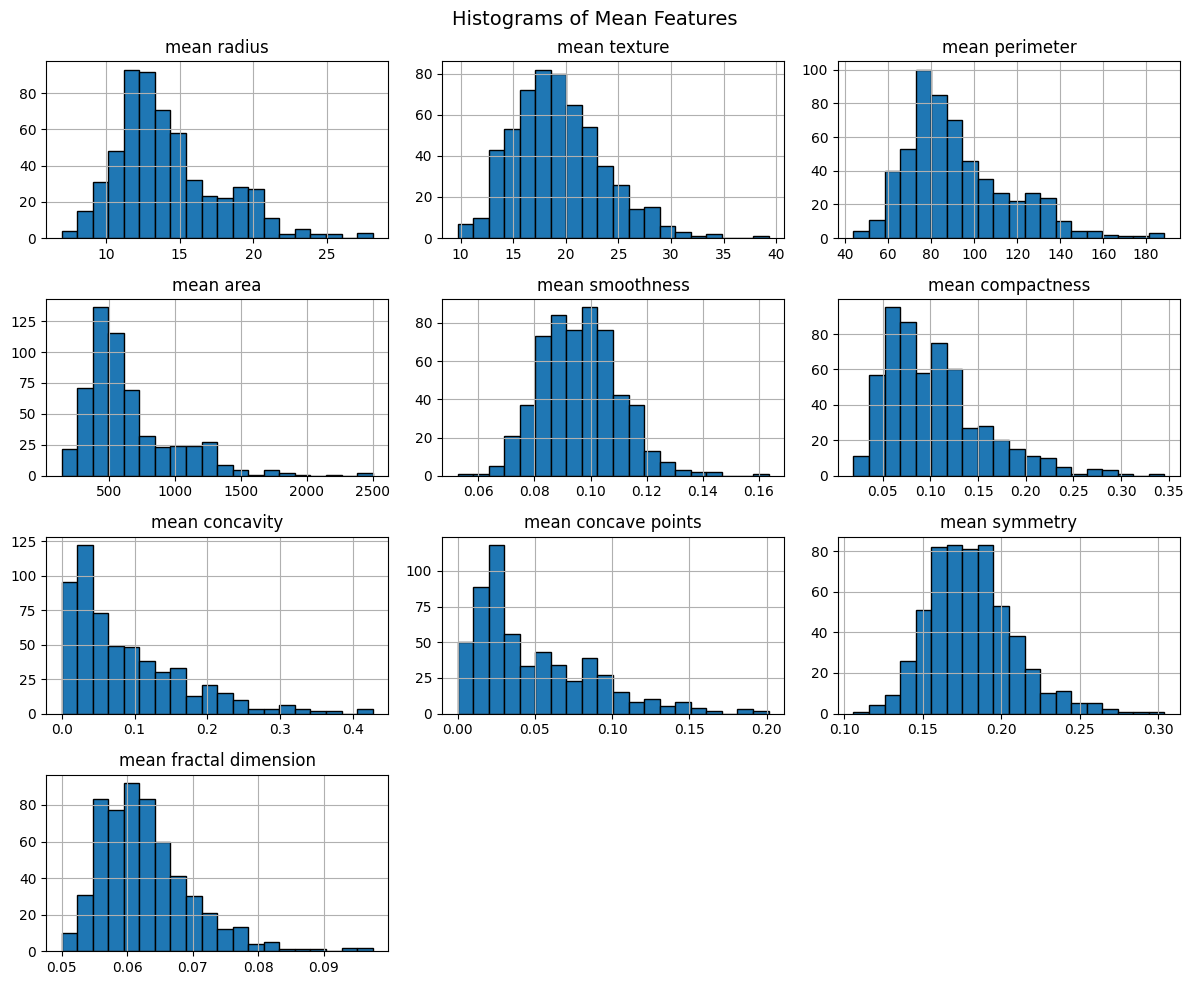

In [34]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
# Histograms of the ten "mean" features
df.filter(like="mean").hist(figsize=(12, 10), bins=20, edgecolor="black")
plt.suptitle("Histograms of Mean Features", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

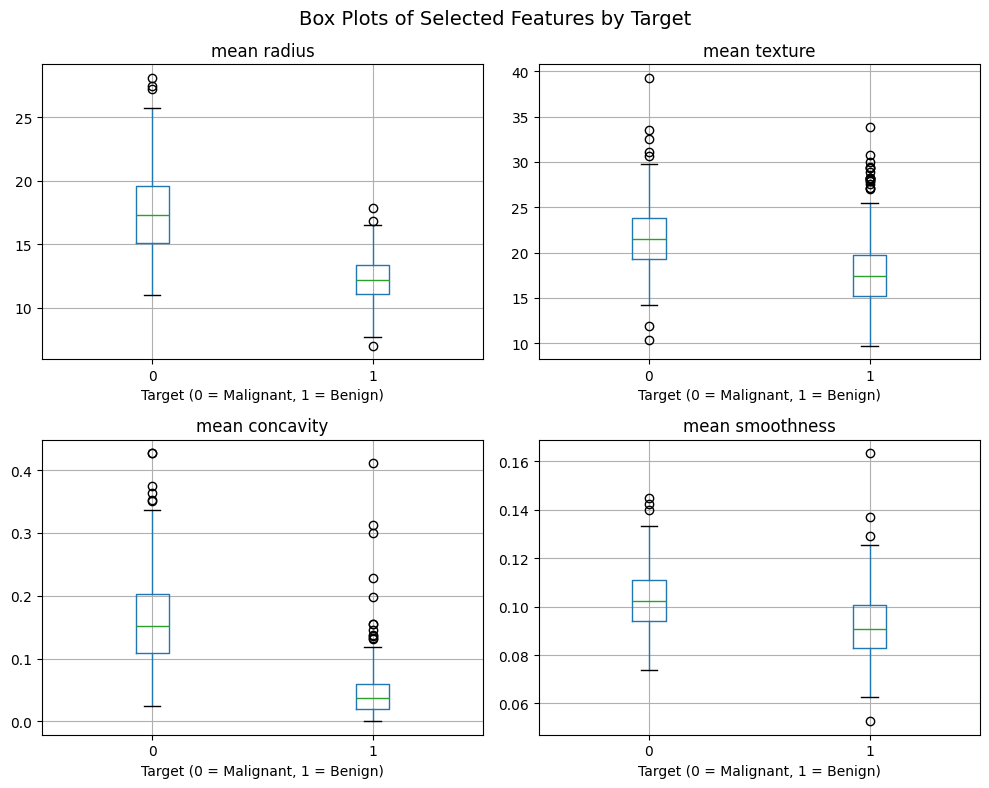

In [35]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
# Box plots grouped by target class
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, feature in enumerate(features):
    df.boxplot(column=feature, by="target", ax=axes[i])
    axes[i].set_title(feature)
    axes[i].set_xlabel("Target (0 = Malignant, 1 = Benign)")

plt.suptitle("Box Plots of Selected Features by Target", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

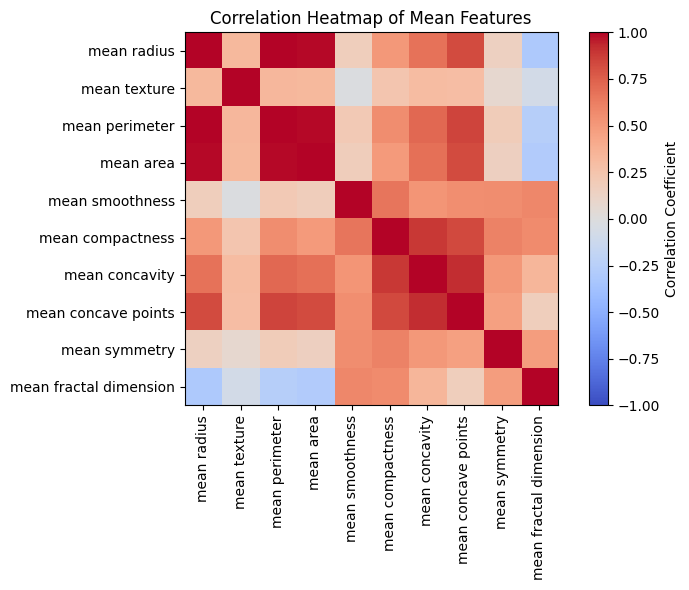

In [36]:
# TODO: correlation matrix of the "mean" features drawn with imshow
# Correlation matrix of mean features
mean_df = df.filter(like="mean")
corr_mean = mean_df.corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr_mean, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")
plt.xticks(range(len(mean_df.columns)), mean_df.columns, rotation=90)
plt.yticks(range(len(mean_df.columns)), mean_df.columns)
plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

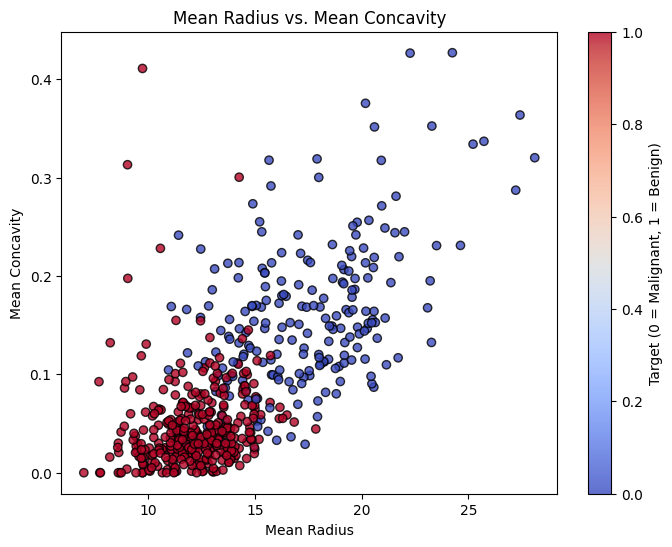

In [37]:
# TODO: coloured scatter plot with axis labels and a colourbar
# Coloured scatter plot with axis labels and a colourbar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.8,
    edgecolors="k"
)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity")
cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Geometric size metrics such as mean radius, mean perimeter, and mean area appear highly redundant due to strong collinearity ($r > 0.95$). Features that separate the classes most clearly include mean concavity, mean concave points, mean perimeter, and mean radius, where malignant samples (0) consistently show significantly higher mean and median values compared to benign cases (1).

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [15]:
# TODO: total missing values and duplicated rows
# Total missing values and duplicated rows
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print("Total missing values:", missing_count)
print("Total duplicate rows:", duplicate_count)

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Total duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [16]:
# TODO: IQR outlier count per feature
# IQR outlier count per feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Identify outliers outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
top_10_outliers = outliers.sort_values(ascending=False).head(10)

print("Top 10 features with most outliers:")
print(top_10_outliers)

Top 10 features with most outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, the outlying rows should not be deleted. In clinical and medical imaging data, extreme feature values often represent genuine physical characteristics associated with malignant tumors rather than measurement errors or noise. Removing these extreme samples would strip away critical signal needed for detecting cancer. Instead, robust scaling techniques or tree-based models can be used to handle feature magnitude variations safely.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [17]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
# Absolute correlation matrix upper triangle
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find columns with correlation > 0.95 to an earlier feature
filter_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
print("Features with correlation > 0.95 to drop:", filter_features)

Features with correlation > 0.95 to drop: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [18]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
# Rank features using SelectKBest (ANOVA F-value)
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = list(kbest_scores.head(10).index)

print("Top 10 SelectKBest Features:\n", kbest_features)

Top 10 SelectKBest Features:
 ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [19]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
# RFE with LogisticRegression on standardized X
X_std = StandardScaler().fit_transform(X)
rfe = RFE(estimator=LogisticRegression(), n_features_to_select=10)
rfe.fit(X_std, y)

rfe_features = list(X.columns[rfe.support_])
print("RFE 10 Selected Features:\n", rfe_features)

RFE 10 Selected Features:
 ['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

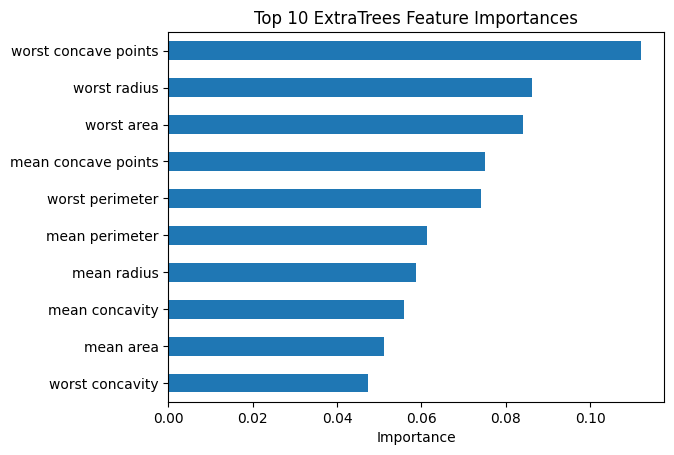

In [20]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
# Feature importance with ExtraTreesClassifier
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=False)
et_features = list(imp.head(10).index)

# Plot top 10 feature importances
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title("Top 10 ExtraTrees Feature Importances")
plt.xlabel("Importance")
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [21]:
# TODO: vote across the three methods
# Keep features chosen by at least two of the three methods
from collections import Counter

all_votes = kbest_features + rfe_features + et_features
counts = Counter(all_votes)

selected = [feature for feature, count in counts.items() if count >= 2]
print(f"Selected {len(selected)} features (voted by >= 2 methods):")
print(selected)

Selected 10 features (voted by >= 2 methods):
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [22]:
# TODO: train_test_split with stratify=y
# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=7, stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [23]:
# TODO: fit both scalers on X_train and print the verifying statistics
# Fit both scalers on X_train only
std_scaler = StandardScaler().fit(X_train)
minmax_scaler = MinMaxScaler().fit(X_train)

X_train_std = std_scaler.transform(X_train)
X_train_minmax = minmax_scaler.transform(X_train)

# Verify statistics for the first 4 features
print("StandardScaler - First 4 Means (approx 0):", np.round(X_train_std[:, :4].mean(axis=0), 2))
print("StandardScaler - First 4 Stds (approx 1):", np.round(X_train_std[:, :4].std(axis=0), 2))
print("MinMaxScaler - First 4 Mins (approx 0):", np.round(X_train_minmax[:, :4].min(axis=0), 2))
print("MinMaxScaler - First 4 Maxs (approx 1):", np.round(X_train_minmax[:, :4].max(axis=0), 2))

StandardScaler - First 4 Means (approx 0): [ 0. -0. -0. -0.]
StandardScaler - First 4 Stds (approx 1): [1. 1. 1. 1.]
MinMaxScaler - First 4 Mins (approx 0): [0. 0. 0. 0.]
MinMaxScaler - First 4 Maxs (approx 1): [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [24]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
# Fit PCA on standardized training data to retain 95% variance
pca = PCA(n_components=0.95)
pca.fit(X_train_std)

print("Number of components retaining 95% variance:", pca.n_components_)
print("Cumulative variance ratio:", np.round(pca.explained_variance_ratio_.cumsum(), 4))

Number of components retaining 95% variance: 10
Cumulative variance ratio: [0.4433 0.6362 0.7284 0.7938 0.8494 0.8904 0.9139 0.9305 0.9443 0.956 ]


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [25]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
# Dictionary of candidate models
models = {
    'LR': LogisticRegression(),
    'LDA': LinearDiscriminantAnalysis(),
    'KNN': KNeighborsClassifier(),
    'CART': DecisionTreeClassifier(random_state=seed),
    'NB': GaussianNB(),
    'SVM': SVC()
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [26]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
# Run spot check on raw and scaled training data
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Build summary DataFrame of mean accuracies
summary = pd.DataFrame({
    'raw': {name: np.mean(scores) for name, scores in raw_results.items()},
    'scaled': {name: np.mean(scores) for name, scores in scaled_results.items()}
})

display(summary)

,raw,scaled
LR,0.938357,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** Distance-based models (KNN, SVM) and gradient-based models (Logistic Regression, LDA) benefit significantly from scaling. These algorithms rely on distance metrics or gradient steps, so unscaled features with large numerical ranges dominate feature calculations. Scaling puts all features on equal footing. Decision trees (CART) and Naive Bayes are scale-invariant because tree splits are invariant to monotonic transformations and Naive Bayes estimates individual probability distributions per feature independently.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [27]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
# Spot-check using selected features only (scaled)
selected_results = spot_check(models, X_train[selected], scale=True)

# Add selected column to summary table
summary['selected'] = {name: np.mean(scores) for name, scores in selected_results.items()}
display(summary)

,raw,scaled,selected
LR,0.938357,0.982319,0.960435
LDA,0.947246,0.947246,0.942995
KNN,0.922947,0.964928,0.942802
CART,0.927633,0.927633,0.925266
NB,0.934058,0.932029,0.951691
SVM,0.898696,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

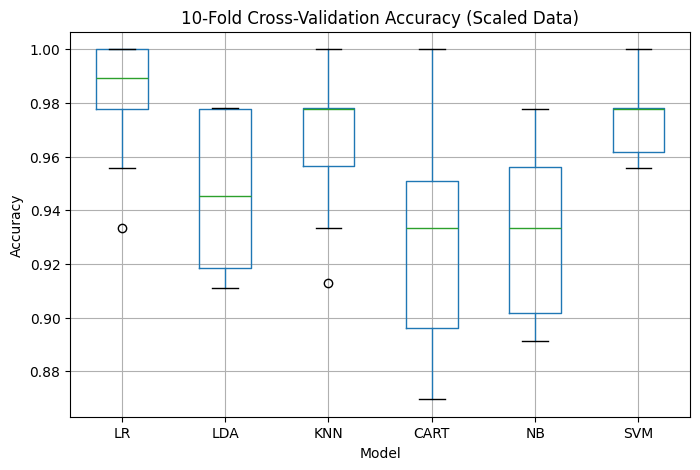

In [28]:
# TODO: box plot of the 10 fold scores per model
# Box plot comparing cross-validation performance across models
results_df = pd.DataFrame(scaled_results)

plt.figure(figsize=(8, 5))
results_df.boxplot()
plt.title("10-Fold Cross-Validation Accuracy (Scaled Data)")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [29]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
# Evaluate best scaled model (e.g., Logistic Regression or SVM) on multiple metrics
best_model = Pipeline([('scale', StandardScaler()), ('model', LogisticRegression())])

scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'recall_malignant': make_scorer(recall_score, pos_label=0)
}

cv_results = cross_validate(best_model, X_train, y_train, cv=kfold, scoring=scoring)

print("Mean Accuracy:", np.mean(cv_results['test_accuracy']))
print("Mean ROC-AUC:", np.mean(cv_results['test_roc_auc']))
print("Mean Recall (Malignant):", np.mean(cv_results['test_recall_malignant']))

Mean Accuracy: 0.9823188405797101
Mean ROC-AUC: 0.9921689365401333
Mean Recall (Malignant): 0.9647058823529413


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [30]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
pipe_svm = Pipeline([('scale', StandardScaler()), ('svm', SVC())])

param_grid_svm = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.001, 0.01, 0.1],
    'svm__kernel': ['rbf', 'linear']
}

grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=kfold, scoring='accuracy')
grid_svm.fit(X_train, y_train)

print("Best SVM Parameters:", grid_svm.best_params_)
print("Best SVM Cross-Validation Accuracy:", grid_svm.best_score_)

Best SVM Parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best SVM Cross-Validation Accuracy: 0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [31]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
pipe_knn = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])

param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'knn__weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=kfold, scoring='accuracy')
grid_knn.fit(X_train, y_train)

print("Best KNN Parameters:", grid_knn.best_params_)
print("Best KNN Cross-Validation Accuracy:", grid_knn.best_score_)

Best KNN Parameters: {'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
Best KNN Cross-Validation Accuracy: 0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [32]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
# Best models from grid search
best_svm = grid_svm.best_estimator_
best_knn = grid_knn.best_estimator_
rf_model = RandomForestClassifier(random_state=seed)

# Define standalone ensemble models
ensemble_models = {
    'RF': rf_model,
    'ET': ExtraTreesClassifier(random_state=seed),
    'GBM': GradientBoostingClassifier(random_state=seed),
    'AB': AdaBoostClassifier(random_state=seed)
}

# Cross-validate four ensemble methods
ensemble_results = spot_check(ensemble_models, X_train, scale=False)

# Add VotingClassifier (hard voting between tuned SVM, tuned KNN, and Random Forest)
voting_model = VotingClassifier(
    estimators=[('svm', best_svm), ('knn', best_knn), ('rf', rf_model)],
    voting='hard'
)
ensemble_results['Voting'] = cross_val_score(voting_model, X_train, y_train, cv=kfold, scoring='accuracy')

# Display mean accuracies
for name, scores in ensemble_results.items():
    print(f"{name}: Mean Accuracy = {scores.mean():.4f}")

RF: Mean Accuracy = 0.9691
ET: Mean Accuracy = 0.9736
GBM: Mean Accuracy = 0.9670
AB: Mean Accuracy = 0.9626
Voting: Mean Accuracy = 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [33]:
# TODO: leaderboard Series
# Collect tuned scores and ensemble scores into a single leaderboard Series
leaderboard_dict = {
    'Tuned SVM': grid_svm.best_score_,
    'Tuned KNN': grid_knn.best_score_,
}

# Add mean accuracy for all ensemble methods
for name, scores in ensemble_results.items():
    leaderboard_dict[name] = np.mean(scores)

# Create and sort Series descending
leaderboard = pd.Series(leaderboard_dict).sort_values(ascending=False)
display(leaderboard)

,0
Tuned SVM,0.980193
Voting,0.978068
ET,0.973575
Tuned KNN,0.969275
RF,0.969130
GBM,0.966957
AB,0.962560


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

=== Final Test Set Performance ===
Test Accuracy: 0.9649

Classification Report:
                precision    recall  f1-score   support

Malignant (0)       0.95      0.95      0.95        42
   Benign (1)       0.97      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.96      0.96       114
 weighted avg       0.96      0.96      0.96       114



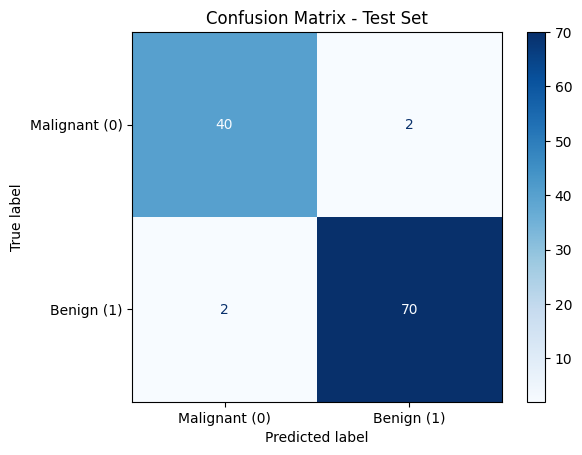

In [38]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
# Pick the leaderboard winner (Tuned SVM)
final_model = grid_svm.best_estimator_

# Fit on the entire training set
final_model.fit(X_train, y_train)

# Predict on the held-out test set
y_pred = final_model.predict(X_test)

# Report metrics
print("=== Final Test Set Performance ===")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=['Malignant (0)', 'Benign (1)']))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Malignant (0)', 'Benign (1)'], cmap=plt.cm.Blues
)
plt.title("Confusion Matrix - Test Set")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [39]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib

# Save the finalized pipeline to a file
joblib.dump(final_model, 'breast_cancer_model.pkl')

# Reload the saved model
loaded_model = joblib.load('breast_cancer_model.pkl')

# Verify predictions match original model on first 5 test samples
original_preds = final_model.predict(X_test[:5])
reloaded_preds = loaded_model.predict(X_test[:5])

print("First 5 Actual Targets (y_test):", y_test.iloc[:5].values)
print("First 5 Original Predictions:   ", original_preds)
print("First 5 Reloaded Predictions:   ", reloaded_preds)

# Confirm identical outputs
assert (original_preds == reloaded_preds).all(), "Predictions do not match!"
print("\nModel saved and reloaded successfully! Predictions match perfectly.")

First 5 Actual Targets (y_test): [0 0 1 0 1]
First 5 Original Predictions:    [0 0 1 0 1]
First 5 Reloaded Predictions:    [0 0 1 0 1]

Model saved and reloaded successfully! Predictions match perfectly.


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.

    **Answer:** Performing feature selection on the entire dataset before cross-validation exposes information from the validation/test folds to the feature selection step (data leakage), which optimistically inflates cross-validation scores. To fix this, encapsulate feature selection inside an sklearn.pipeline.Pipeline alongside the classifier. This ensures feature selection parameters are re-fitted strictly on the training split of each cross-validation fold and applied downstream without leaking test fold information.

2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?

    **Answer:** In a clinical setting, Recall (Sensitivity) on the malignant class (alongside ROC-AUC or PR-AUC) should be reported. Accuracy alone is insufficient because it treats all classification errors equally and can mask poor detection rates on imbalanced datasets. Misclassifying a malignant tumor as benign (False Negative) delays critical treatment and carries far higher stakes than ordering a follow-up test for a benign case (False Positive).

3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)

    **Answer:** When two models differ by only 0.3% in cross-validation accuracy, the decision should be guided by:
    
    1. Variance across folds: Prefer the model with lower standard deviation to ensure stable performance on unseen data.
    
    2. Interpretability: In clinical contexts, simpler and transparent models (e.g., Logistic Regression) are easier for practitioners to trust and explain than complex black-box models.
    
    3. Resource Efficiency: Choose the model with lower training/inference latency and lower memory requirements if performance gains are marginal.

4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?

    **Answer:**
    * Smaller dataset: Increases the risk of overfitting, leads to higher variance across cross-validation folds, and reduces statistical power. Mitigations require stronger regularization or repeated stratified cross-validation.
    
    * Imbalanced dataset: Renders accuracy misleading. Metrics like Precision, Recall, F1-Score, and PR-AUC become critical, and techniques such as class weighting adjustments or resampling methods (e.g., SMOTE) must be applied.

5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

    **Answer:** When repeating this workflow with a new dataset (e.g., loaded from an ARFF file using scipy.io.arff):
    
    * Data Loading & Preprocessing: The parsing step changes to handle categorical variables (encoding via OneHotEncoder or OrdinalEncoder) and missing value imputation.
    
    * Exploratory Data Analysis: Visualizations must adapt to categorical vs. numeric distributions.
    
    * Pipeline Configuration: Scaling and feature selection steps must be tailored to the specific variable types of the new domain.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.